# **Прикладные задачи МО на графах (версия для магистров). 17.09.2025**

## **Случайные блуждания на графах. PageRank**

Библиотека для работы с графами [NetworkX](https://networkx.org/documentation/stable/)

Руководство [Tutorial](https://networkx.org/documentation/stable/tutorial.html)

In [ ]:
# Импортируем библиотеку для работы с графами и не только
import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy import linalg as LA

## Центральность по собственному вектору

* Для неорграфа: $Ax = \lambda x$
* Для орграфа:
* Исходящие рёбра - центральность (centrality): $Ax = \lambda x $ (правый собственный вектор)
* Входящие рёбра - престиж (prestige): $xA = A^{T}x = \lambda x $  (левый собственный вектор)

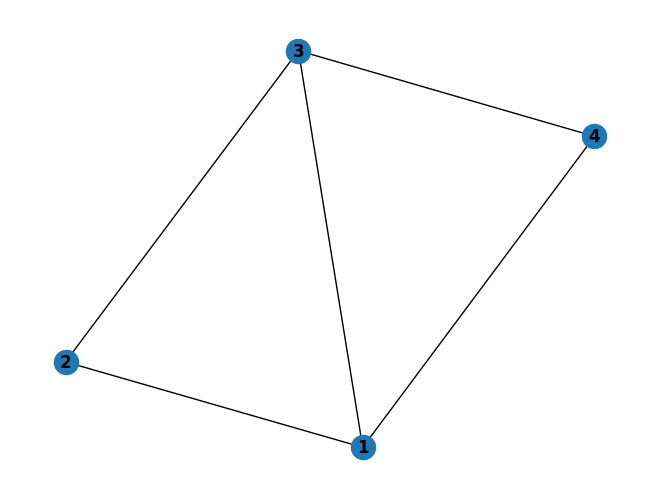

In [ ]:
# Создадим неорграф
G = nx.Graph()
G.add_edges_from([(1, 2), (1, 3), (3, 2), (3, 4), (4, 1)])

nx.draw(G, with_labels=True, font_weight='bold')

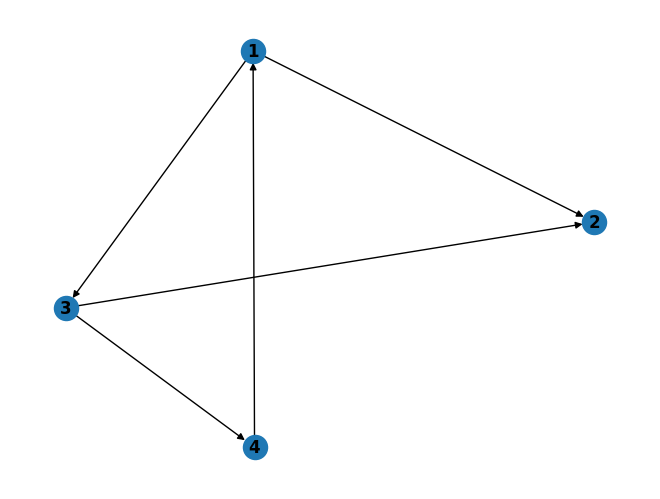

In [ ]:
# Создадим орграф
H = nx.DiGraph()
H.add_edges_from([(1, 2), (1, 3), (3, 2), (3, 4), (4, 1)])

nx.draw(H, with_labels=True, font_weight='bold')

In [ ]:
# Центральность по собственному вектору для неорграфа G
nx.eigenvector_centrality(G)

{1: 0.5573453897277424,
 2: 0.43516217270028296,
 3: 0.5573453897277424,
 4: 0.43516217270028296}

In [ ]:
# матрица смежности (сразу сохраняем, как не разряженную, чтобы работать с ней)
A = nx.adjacency_matrix(G).todense()
A

array([[0, 1, 1, 1],
       [1, 0, 1, 0],
       [1, 1, 0, 1],
       [1, 0, 1, 0]])

In [ ]:
# собственные числа и вектора A
LA. eig(A)

EigResult(eigenvalues=array([ 2.56155281, -1.        , -1.56155281,  0.        ]), eigenvectors=array([[-5.57345410e-01, -7.07106781e-01, -4.35162146e-01,
        -2.81611365e-17],
       [-4.35162146e-01,  3.55681436e-16,  5.57345410e-01,
        -7.07106781e-01],
       [-5.57345410e-01,  7.07106781e-01, -4.35162146e-01,
        -1.24758465e-17],
       [-4.35162146e-01,  3.55681436e-16,  5.57345410e-01,
         7.07106781e-01]]))

In [ ]:
# максимальный собственный вектор (соответветсвующий максимальному собственному числу)
LA.eig(A)[1][:, 0]

array([-0.55734541, -0.43516215, -0.55734541, -0.43516215])

In [ ]:
# подсчет итеративным способом

x0 = np.array([1/4, 1/4, 1/4, 1/4])

for i in range(10):
  x = LA.matrix_power(A, i).dot(x0)
  print(f'Итерация {i}: A^{i}.x{i} = {x/LA.norm(x)}')

Итерация 0: A^0.x0 = [0.5 0.5 0.5 0.5]
Итерация 1: A^1.x1 = [0.58834841 0.39223227 0.58834841 0.39223227]
Итерация 2: A^2.x2 = [0.53687549 0.46017899 0.53687549 0.46017899]
Итерация 3: A^3.x3 = [0.56926044 0.41945506 0.56926044 0.41945506]
Итерация 4: A^4.x4 = [0.54986747 0.4445737  0.54986747 0.4445737 ]
Итерация 5: A^5.x5 = [0.56182544 0.42936253 0.56182544 0.42936253]
Итерация 6: A^6.x6 = [0.55458487 0.43867485 0.55458487 0.43867485]
Итерация 7: A^7.x7 = [0.55901737 0.43301221 0.55901737 0.43301221]
Итерация 8: A^8.x8 = [0.5563221  0.43646961 0.5563221  0.43646961]
Итерация 9: A^9.x9 = [0.55796773 0.43436392 0.55796773 0.43436392]


In [ ]:
# Центральность по собственному вектору для орграфа H
nx.eigenvector_centrality(H)

{1: 0.37796529690751635,
 2: 0.7559277101686634,
 3: 0.37796529690751635,
 4: 0.37796529690751635}

In [ ]:
# матрица смежности графа H
B = nx.adjacency_matrix(H).todense()
B

array([[0, 1, 1, 0],
       [0, 0, 0, 0],
       [0, 1, 0, 1],
       [1, 0, 0, 0]])

In [ ]:
LA.eig(B)

EigResult(eigenvalues=array([-0.5+0.8660254j, -0.5-0.8660254j,  1. +0.j       ,  0. +0.j       ]), eigenvectors=array([[ 2.88675135e-01-0.5j,  2.88675135e-01+0.5j, -5.77350269e-01+0.j ,
        -5.07807461e-17+0.j ],
       [ 0.00000000e+00+0.j ,  0.00000000e+00-0.j ,  0.00000000e+00+0.j ,
         5.77350269e-01+0.j ],
       [ 2.88675135e-01+0.5j,  2.88675135e-01-0.5j, -5.77350269e-01+0.j ,
        -5.77350269e-01+0.j ],
       [-5.77350269e-01+0.j , -5.77350269e-01-0.j , -5.77350269e-01+0.j ,
        -5.77350269e-01+0.j ]]))

In [ ]:
# подсчет итеративным способом

x0 = np.array([1/4, 1/4, 1/4, 1/4])

for i in range(10):
  x = LA.matrix_power(B, i).dot(x0)
  print(f'Итерация {i}: B^{i}.x{i} = {x/LA.norm(x)}')

Итерация 0: B^0.x0 = [0.5 0.5 0.5 0.5]
Итерация 1: B^1.x1 = [0.66666667 0.         0.66666667 0.33333333]
Итерация 2: B^2.x2 = [0.66666667 0.         0.33333333 0.66666667]
Итерация 3: B^3.x3 = [0.33333333 0.         0.66666667 0.66666667]
Итерация 4: B^4.x4 = [0.66666667 0.         0.66666667 0.33333333]
Итерация 5: B^5.x5 = [0.66666667 0.         0.33333333 0.66666667]
Итерация 6: B^6.x6 = [0.33333333 0.         0.66666667 0.66666667]
Итерация 7: B^7.x7 = [0.66666667 0.         0.66666667 0.33333333]
Итерация 8: B^8.x8 = [0.66666667 0.         0.33333333 0.66666667]
Итерация 9: B^9.x9 = [0.33333333 0.         0.66666667 0.66666667]


In [ ]:
# Матрица B несимметричная
# подсчет итеративным способом, но умножаем слева (учитываем влияние входящих рёбер (!))

x0 = np.array([1/4, 1/4, 1/4, 1/4])

for i in range(10):
  x = x0.dot(LA.matrix_power(B, i))
  print(f'Итерация {i}:x{i}.B^{i} = {x/LA.norm(x)}')

Итерация 0:x0.B^0 = [0.5 0.5 0.5 0.5]
Итерация 1:x1.B^1 = [0.37796447 0.75592895 0.37796447 0.37796447]
Итерация 2:x2.B^2 = [0.37796447 0.75592895 0.37796447 0.37796447]
Итерация 3:x3.B^3 = [0.37796447 0.75592895 0.37796447 0.37796447]
Итерация 4:x4.B^4 = [0.37796447 0.75592895 0.37796447 0.37796447]
Итерация 5:x5.B^5 = [0.37796447 0.75592895 0.37796447 0.37796447]
Итерация 6:x6.B^6 = [0.37796447 0.75592895 0.37796447 0.37796447]
Итерация 7:x7.B^7 = [0.37796447 0.75592895 0.37796447 0.37796447]
Итерация 8:x8.B^8 = [0.37796447 0.75592895 0.37796447 0.37796447]
Итерация 9:x9.B^9 = [0.37796447 0.75592895 0.37796447 0.37796447]


In [ ]:
LA.eig(B.T)[1][:, 3]

array([-0.37796447+0.j, -0.75592895+0.j, -0.37796447+0.j, -0.37796447+0.j])

## Задание 1

1. Вычислите метрики центральности для орграфов с рёбрами
  * (a, a), (a, b), (b, a), (b, c), (c, b)
  * (a, b), (b, c), (c, b)
  * (a, b), (b, c)

2. Для графов на рисунке проверьте, будет ли процесс случайного блуждания сходящимся? Проверьте разные начальные положения "walker"-a.
* Если да, то к каким значениям вектора вероятностей?
* Как можно интерпретировать полученный результаты? Есть ли качественное отличие в результатах и почему?

3. Можно ли добавить к одному из графов одно ребро так, чтобы результат были качественно похожи.

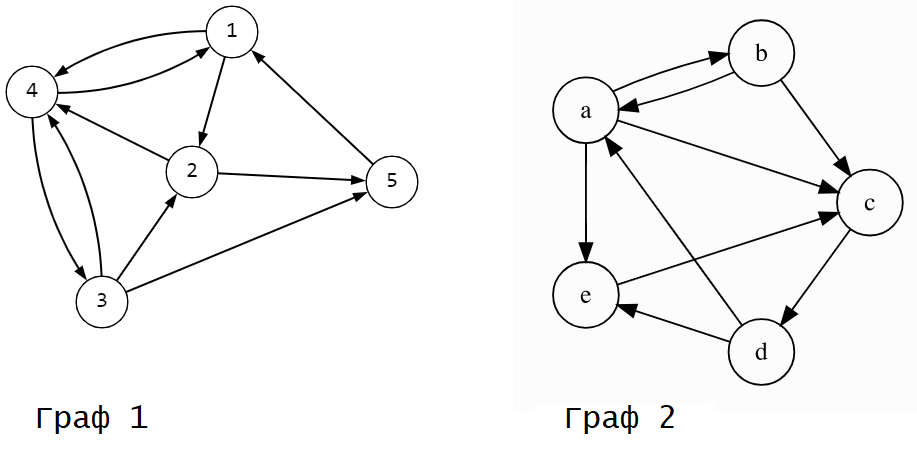


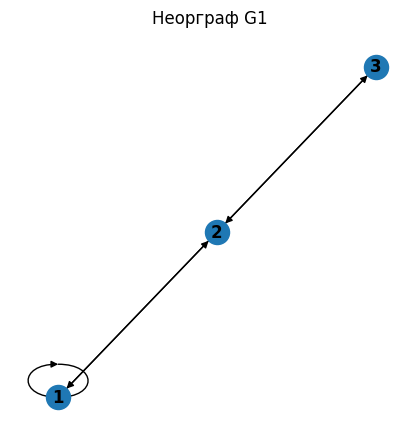

{1: 0.7369751022345074, 2: 0.5910096738672207, 3: 0.3279866827811746}


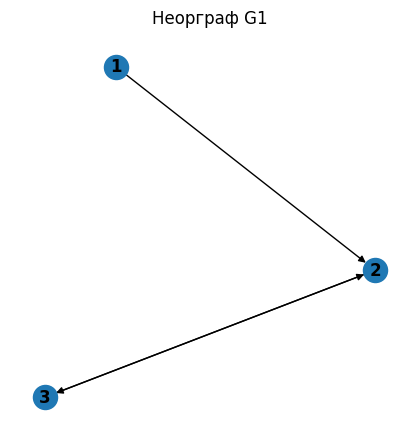

{1: 8.991333398854427e-07, 2: 0.7071072307527887, 3: 0.7071063316194488}


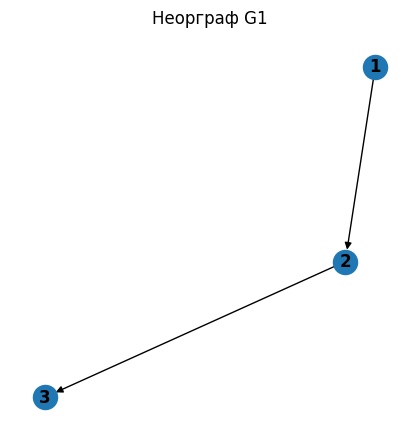

Итерация 0: B^0.x0 = [0.57735027 0.57735027 0.57735027]
Итерация 1: B^1.x1 = [0.70710678 0.70710678 0.        ]
Итерация 2: B^2.x2 = [1. 0. 0.]
Итерация 3: B^3.x3 = [nan nan nan]
Итерация 4: B^4.x4 = [nan nan nan]
Итерация 0:x0.B^0 = [0.57735027 0.57735027 0.57735027]
Итерация 1:x1.B^1 = [0.         0.70710678 0.70710678]
Итерация 2:x2.B^2 = [0. 0. 1.]
Итерация 3:x3.B^3 = [nan nan nan]
Итерация 4:x4.B^4 = [nan nan nan]


/tmp/ipython-input-218688928.py:38: RuntimeWarning: invalid value encountered in divide
  print(f'Итерация {i}: B^{i}.x{i} = {x/LA.norm(x)}')
/tmp/ipython-input-218688928.py:46: RuntimeWarning: invalid value encountered in divide
  print(f'Итерация {i}:x{i}.B^{i} = {x/LA.norm(x)}')


In [ ]:
G1 = nx.DiGraph()
G1.add_edges_from([(1,1),(1, 2), (2, 1), (2, 3), (3, 2)])

plt.figure(figsize=(4,4))
nx.draw(G1, with_labels=True, font_weight='bold')
plt.title("Неорграф G1")
plt.show()

# Центральность по собственному вектору G
print(nx.eigenvector_centrality(G1))

G2 = nx.DiGraph()
G2.add_edges_from([(1, 2), (2, 3), (3, 2)])

plt.figure(figsize=(4,4))
nx.draw(G2, with_labels=True, font_weight='bold')
plt.title("Неорграф G1")
plt.show()

# Центральность по собственному вектору G
print(nx.eigenvector_centrality(G2))

G3 = nx.DiGraph()
G3.add_edges_from([(1, 2),(2, 3)])

plt.figure(figsize=(4,4))
nx.draw(G3, with_labels=True, font_weight='bold')
plt.title("Неорграф G1")
plt.show()

A = nx.adjacency_matrix(G3).todense()
# подсчет итеративным способом

x0 = np.array([1/5, 1/5, 1/5])

for i in range(5):
  x = LA.matrix_power(A, i).dot(x0)
  print(f'Итерация {i}: B^{i}.x{i} = {x/LA.norm(x)}')

# подсчет итеративным способом, но умножаем слева (учитываем влияние входящих рёбер (!))

x0 = np.array([1/5, 1/5, 1/5])

for i in range(5):
  x = x0.dot(LA.matrix_power(A, i))
  print(f'Итерация {i}:x{i}.B^{i} = {x/LA.norm(x)}')


In [ ]:
def random_walk_convergence(graph, start_node, steps=1000):
    nodes = list(graph.nodes)
    node_index = {node: i for i, node in enumerate(nodes)}
    n = len(nodes)
    P = np.zeros((n, n))

    # Строим матрицу переходов
    for i, node in enumerate(nodes):
        neighbors = list(graph.successors(node))
        if neighbors:
            prob = 1 / len(neighbors)
            for neighbor in neighbors:
                j = node_index[neighbor]
                P[i][j] = prob
        else:
            # Переход к самому себе, если нет исходящих рёбер
            P[i][i] = 1.0

    # Инициализация вероятностей
    v = np.zeros(n)
    v[node_index[start_node]] = 1.0

    # Эволюция вероятностей
    for _ in range(steps):
        v = v @ P

    return dict(zip(nodes, v))

# Граф 1
G4 = nx.DiGraph()
G4.add_edges_from([(1, 2),(1,4), (5,1), (3, 2), (2, 5), ( 2,4), (3,4),(3,5), (4, 1), (4, 3)])

# Граф 2
G5 = nx.DiGraph()
G5.add_edges_from([('a', 'b'), ('a', 'c'), ('a', 'e'), ('b','a'),('b', 'c'), ('c', 'd'), ('d', 'e'), ('d','a'),('e', 'c')])

# Проверка сходимости
print("Граф 1:")
for start in G4.nodes:
    result = random_walk_convergence(G4, start)
    print(f"Старт с узла {start}: {result}")

print("\nГраф 2:")
for start in G5.nodes:
    result = random_walk_convergence(G5, start)
    print(f"Старт с узла {start}: {result}")

# Добавление ребра для качественного сходства
G4_modified = G4.copy()
G4_modified.add_edge(5, 3)  # Замыкаем цикл
# G1_modified.add_edge(5, 4)
print("\nГраф 1 с добавленным ребром (5 - 3):")
for start in G4_modified.nodes:
    result = random_walk_convergence(G4_modified, start)
    print(f"Старт с узла {start}: {result}")


Граф 1:
Старт с узла 1: {1: np.float64(0.2727272727272725), 2: np.float64(0.18181818181818166), 4: np.float64(0.2727272727272725), 5: np.float64(0.13636363636363624), 3: np.float64(0.13636363636363624)}
Старт с узла 2: {1: np.float64(0.2727272727272726), 2: np.float64(0.1818181818181817), 4: np.float64(0.2727272727272726), 5: np.float64(0.1363636363636363), 3: np.float64(0.1363636363636363)}
Старт с узла 4: {1: np.float64(0.2727272727272725), 2: np.float64(0.18181818181818166), 4: np.float64(0.2727272727272725), 5: np.float64(0.13636363636363624), 3: np.float64(0.13636363636363624)}
Старт с узла 5: {1: np.float64(0.2727272727272725), 2: np.float64(0.18181818181818166), 4: np.float64(0.2727272727272725), 5: np.float64(0.13636363636363624), 3: np.float64(0.13636363636363624)}
Старт с узла 3: {1: np.float64(0.2727272727272727), 2: np.float64(0.1818181818181818), 4: np.float64(0.2727272727272727), 5: np.float64(0.13636363636363635), 3: np.float64(0.13636363636363635)}

Граф 2:
Старт с узла

Чтобы сделать результаты качественно похожими, нужно добиться того, чтобы все узлы Графа 1 участвовали в цикле.

Например, если добавить ребро 5 - 3 в Граф 1, то получится цикл: 5 - 3 - 4 - 1 - 2 - 5

## PageRank by Google

*   Узел важен, если на него указывают другие важные узлы
*   "Телепортация"\, на случайную страницу (переход не по ссылке):
  * с  вероятностью $\alpha$ --- переход по ссылке;
  * с  вероятностью $(1 - \alpha)$ --- "телепортация".
  * из вершин-стоков телепортация с вероятностью $1$
* PageRank (Brin-Page, 1998)
$$ x_j = \alpha \sum_{(i,j) \in E}  \frac{x_i}{ d^{out}_i }+ (1-\alpha)\frac{1}{n} $$

* В матричном виде
    $$ \mathbf{x}=\alpha \cdot  \mathbf{P}\mathbf{x} + (1-\alpha)\cdot \left[\frac{1}{n}\right]_{n\times n} $$

  $$ \mathbf{P=A^T D = D^{-1} A}, \quad D_{ii}=diag\{\max(d_i^{out},1)\}$$

* Google-matrix  $\mathbf{G} = \alpha \cdot \mathbf{P} + (1-\alpha)\cdot \left[\frac{1}{n}\right]_{n\times n}$

* Обычно $\alpha = 0.8, 0.85, 0.9$

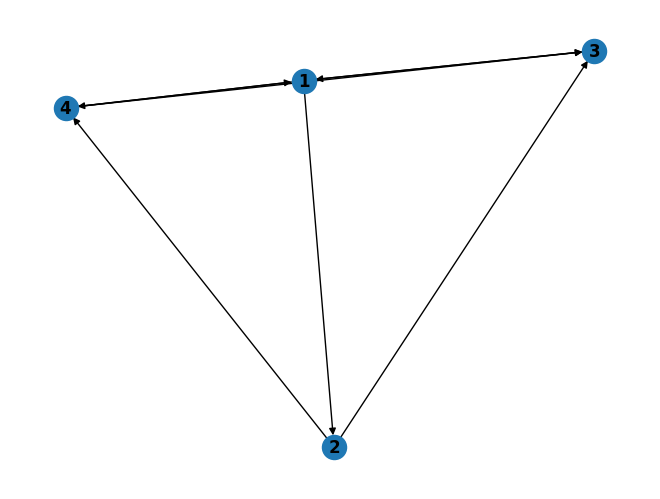

In [ ]:
# Создадим орграф
F = nx.DiGraph()
F.add_edges_from([(1, 2), (1, 3), (1, 4), (2, 3), (2, 4), (3, 1), (4, 1), (4, 3)])

nx.draw(F, with_labels=True, font_weight='bold')

In [ ]:
# матрица смежности графа F
Adj_matr_F = nx.adjacency_matrix(F).todense()
Adj_matr_F

array([[0, 1, 1, 1],
       [0, 0, 1, 1],
       [1, 0, 0, 0],
       [1, 0, 1, 0]])

In [ ]:
# Диагональная матрица степеней
# для вершины без исходящих рёбер задали deg_out = 1
F_node_degrees = [max([degree[1], 1]) for degree in F.out_degree()]
Diag_matr_F = np.diag(F_node_degrees)
Diag_matr_F

array([[3, 0, 0, 0],
       [0, 2, 0, 0],
       [0, 0, 1, 0],
       [0, 0, 0, 2]])

In [ ]:
Diag_matr_inv_F = LA.inv(Diag_matr_F)
Diag_matr_inv_F

array([[0.33333333, 0.        , 0.        , 0.        ],
       [0.        , 0.5       , 0.        , 0.        ],
       [0.        , 0.        , 1.        , 0.        ],
       [0.        , 0.        , 0.        , 0.5       ]])

In [ ]:
(Diag_matr_inv_F.dot(Adj_matr_F))

array([[0.        , 0.33333333, 0.33333333, 0.33333333],
       [0.        , 0.        , 0.5       , 0.5       ],
       [1.        , 0.        , 0.        , 0.        ],
       [0.5       , 0.        , 0.5       , 0.        ]])

In [ ]:
# Google матрица
alpha = 0.85
F_node_num = nx.number_of_nodes(F)

Google_matr_F = alpha * (Diag_matr_inv_F.dot(Adj_matr_F)) + (1 - alpha) * np.ones(np.shape(Adj_matr_F))/F_node_num
Google_matr_F

array([[0.0375    , 0.32083333, 0.32083333, 0.32083333],
       [0.0375    , 0.0375    , 0.4625    , 0.4625    ],
       [0.8875    , 0.0375    , 0.0375    , 0.0375    ],
       [0.4625    , 0.0375    , 0.4625    , 0.0375    ]])

In [ ]:
# проверим ...
nx.google_matrix(F)

array([[0.0375    , 0.32083333, 0.32083333, 0.32083333],
       [0.0375    , 0.0375    , 0.4625    , 0.4625    ],
       [0.8875    , 0.0375    , 0.0375    , 0.0375    ],
       [0.4625    , 0.0375    , 0.4625    , 0.0375    ]])

In [ ]:
# Подсчет PageRank итеративным способом

x0 = np.array([1/4, 1/4, 1/4, 1/4])

for i in range(10):
  x = x0.dot(LA.matrix_power(nx.google_matrix(F, alpha = 0.7), i))
  print(f'Итерация {i}: x{i} = {x}')

Итерация 0: x0 = [0.25 0.25 0.25 0.25]
Итерация 1: x1 = [0.3375     0.13333333 0.30833333 0.22083333]
Итерация 2: x2 = [0.368125   0.15375    0.27770833 0.20041667]
Итерация 3: x3 = [0.33954167 0.16089583 0.28485417 0.21470833]
Итерация 4: x4 = [0.34954583 0.15422639 0.28568785 0.21053993]
Итерация 5: x5 = [0.34867047 0.15656069 0.28422891 0.21053993]
Итерация 6: x6 = [0.34764921 0.15635644 0.28484166 0.21115269]
Итерация 7: x7 = [0.3482926  0.15611815 0.28474634 0.2108429 ]
Итерация 8: x8 = [0.34811746 0.15626827 0.28470464 0.21090963]
Итерация 9: x9 = [0.34811162 0.15622741 0.28473967 0.2109213 ]


In [ ]:
# проверим ...
nx.pagerank(F, alpha = 0.85)

{1: 0.3681509531104541,
 2: 0.14180962694364857,
 3: 0.28796129337481535,
 4: 0.20207812657108176}

## Задание 2

1. Вычислите PageRank для следующих графов при $\alpha = 1, 0.85, 0.5, 0$. Как можно объяснить полученные результаты?

* Графы из задания 1.

* (2, 3), (2, 5), (3, 1), (4, 2), (4, 5), (5, 4), (6, 3)

* (2, 1), (3, 1), (4, 2), (5, 2), (6, 3), (7, 3), (8, 3)

In [ ]:
H1 = nx.DiGraph()
H1.add_edges_from([(2,3), (2,5), (3,1), (4,2), (4,5), (5,4), (6,3)])

H2 = nx.DiGraph()
H2.add_edges_from([(2,1), (3,1), (4,2), (5,2), (6,3), (7,3), (8,3)])

def compute_pagerank(graph, alphas=[1,0.85,0.5,0]):
    results = {}
    for alpha in alphas:
        pr = nx.pagerank(graph, alpha=alpha)
        results[alpha] = pr
    return results

print("PageRank для G4:")
print(compute_pagerank(G4))

print("\nPageRank для G5:")
print(compute_pagerank(G5))

print("\nPageRank для H1:")
print(compute_pagerank(H1))

print("\nPageRank для H2:")
print(compute_pagerank(H2))


PageRank для G4:
{1: {1: 0.2727276922509927, 2: 0.18181841416323152, 4: 0.27272702265500526, 5: 0.13636331672764906, 3: 0.13636355420312155}, 0.85: {1: 0.2666741962178663, 2: 0.1832882175341794, 4: 0.26118563962326913, 5: 0.14784846515454472, 3: 0.14100348147014047}, 0.5: {1: 0.2453838536768784, 2: 0.187793394175086, 4: 0.23474149900208777, 5: 0.17339575575212393, 3: 0.15868549739382395}, 0: {1: 0.2, 2: 0.2, 4: 0.2, 5: 0.2, 3: 0.2}}

PageRank для G5:
{1: {'a': 0.17142924413329896, 'b': 0.057142778219347136, 'c': 0.2857134519556003, 'e': 0.20000071216480247, 'd': 0.2857138135269508}, 0.85: {'a': 0.17796438691281852, 'b': 0.08042302608147664, 'c': 0.2796782484033884, 'e': 0.19420770729738926, 'd': 0.2677266313049273}, 0.5: {'a': 0.19033215151674737, 'b': 0.13172212207377312, 'c': 0.2592148528777141, 'e': 0.18912375118288757, 'd': 0.22960712234887784}, 0: {'a': 0.2, 'b': 0.2, 'c': 0.2, 'e': 0.2, 'd': 0.2}}

PageRank для H1:
{1: {2: 0.16216160178093064, 3: 0.1351360053494521, 5: 0.24324218

Граф G4

Здесь узлы 1 и 4 получают наибольший вес, так как они участвуют в циклах и имеют много входящих рёбер. Узлы 3 и 5 остаются менее значимыми. При уменьшении 𝛼 распределение сглаживается, но структура сохраняется — лидируют 1 и 4.

Граф G5

В этом графе узлы c и d доминируют, так как они включены в несколько циклов. Узел b остаётся слабым, а узлы a и e занимают промежуточное положение. При снижении 𝛼 различия уменьшаются, но c и d всё равно важнее.

Граф H1

Узлы 4 и 5 образуют цикл и получают наибольший вес. Узел 6 почти исчезает при 𝛼=1
, так как у него только исходящее ребро. При уменьшении 𝛼 он получает небольшой вес за счёт телепортации, но остаётся на периферии.

Граф H2

Это 'звезда': почти все пути ведут к узлу 1, поэтому он концентрирует большую часть веса. Узел 3 получает средний вес, а остальные узлы остаются слабыми. При уменьшении 𝛼 распределение сглаживается, но узел 1 всё равно остаётся главным.

α = 1 - распределение полностью зависит от структуры графа: циклы и узлы с входами доминируют, источники исчезают.

α = 0 - все узлы равны, PageRank = 1/𝑛.

α = 0.85 - важные узлы выделяются, но все получают ненулевой вес.

α = 0.5 - различия сглаживаются, распределение ближе к равномерному.

Циклические графы имеют более равномерное распределение.

'Звёздные' графы имеют один узел, концентрирующи почти весь вес.

# Hyperlink Induced Topic Search (HITS)


* **Authorities**, авторитетный/оригинальный документ, контент (автор, оригинальная статья, исследование)
* Authority centrality (входящие связи)

    $$a_{i} = \alpha \sum_j A_{ji} h_j$$

* **Hubs**, xаб-документ (хаб-страница, посредник, обзорная статья)
* Hub centrality (исходящие связи)
* Хорошие обзоры упоминают  хорошие оригинальные статьи
$$h_{i} = \beta  \sum_j A_{ij} a_j$$
* В матричном виде

$$
  \mathbf{a}  =  \alpha \mathbf{A}^T \mathbf{h}, \qquad
  \mathbf{h}  =  \beta \mathbf{A} \mathbf{a}
$$

$$
  (\mathbf{A}^T \mathbf{A} )\mathbf{a}  =  \lambda  \mathbf{a}, \qquad
  (\mathbf{A} \mathbf{A}^T )\mathbf{h}  = \lambda \mathbf{h},\qquad
  \lambda =  (\alpha \beta)^{-1}
$$

* $\mathbf{h} = \mathbf{A} a$ - собственный вектор матрицы $\mathbf{A} \mathbf{A}^T$

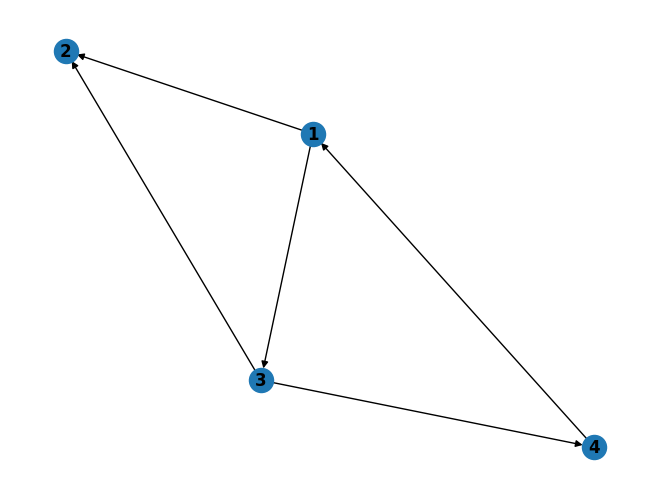

In [ ]:
# Создадим орграф
H = nx.DiGraph()
H.add_edges_from([(1, 2), (1, 3),  (3, 2), (3, 4), (4, 1)])

nx.draw(H, with_labels=True, font_weight='bold')

In [ ]:
# матрица смежности графа H
B = nx.adjacency_matrix(H).todense()

# HITS матрица
HITS_matr = B.dot(B.T)
HITS_matr

array([[2, 0, 1, 0],
       [0, 0, 0, 0],
       [1, 0, 2, 0],
       [0, 0, 0, 1]])

In [ ]:
LA.eig(HITS_matr)

EigResult(eigenvalues=array([3., 1., 0., 1.]), eigenvectors=array([[ 0.70710678, -0.70710678,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  1.        ,  0.        ],
       [ 0.70710678,  0.70710678,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  1.        ]]))

In [ ]:
# Метрики hubs и auths
hubs_H = LA.eig(HITS_matr)[1][:, 0]
print(f'Метрики hubs для графа H: {hubs_H}')

auths_H = (B.T).dot(hubs_H)
print(f'Метрики auths для графа H: {auths_H}')

Метрики hubs для графа H: [0.70710678 0.         0.70710678 0.        ]
Метрики auths для графа H: [0.         1.41421356 0.70710678 0.70710678]


In [ ]:
# С точностью до нормирования вектора
nx.hits(H)

({1: 0.5000000000000001, 2: 0.0, 3: 0.5, 4: 0.0},
 {1: 0.0, 2: 0.5, 3: 0.25000000000000006, 4: 0.24999999999999994})

## Задание 3

Вычислите метрики Hub и Authority для графов (файлы graph_xx.txt)

1. Подумайте над интерпритацией полученных результатов
2. Как можно объяснить равенство значений Authority centrality для узлов 3 и 5 графа 4 ?
3. Как можно увеличить метрики для узла 1 в графах 1, 2 и 3

In [ ]:
files = [f"graph_{i}.txt" for i in range(1, 7)]

In [ ]:
def read_graph_from_file(filename):
    G = nx.DiGraph()
    with open(filename) as f:
        for line in f:
            if line.strip():
                u, v = line.strip().split(",")
                G.add_edge(int(u), int(v))
    return G

In [ ]:
def compute_hits(graph):
    hubs, authorities = nx.hits(graph, max_iter=1000, normalized=True)
    return hubs, authorities


In [ ]:
def draw_graph(G, title):
    plt.figure(figsize=(14, 8))
    pos = nx.spring_layout(G)  # расположение узлов
    nx.draw_networkx_nodes(G, pos, node_size=700, node_color="skyblue")
    nx.draw_networkx_edges(G, pos, arrowstyle="->", arrowsize=20)
    nx.draw_networkx_labels(G, pos, font_size=12, font_weight="bold")
    plt.title(title)
    plt.axis("off")
    plt.show()



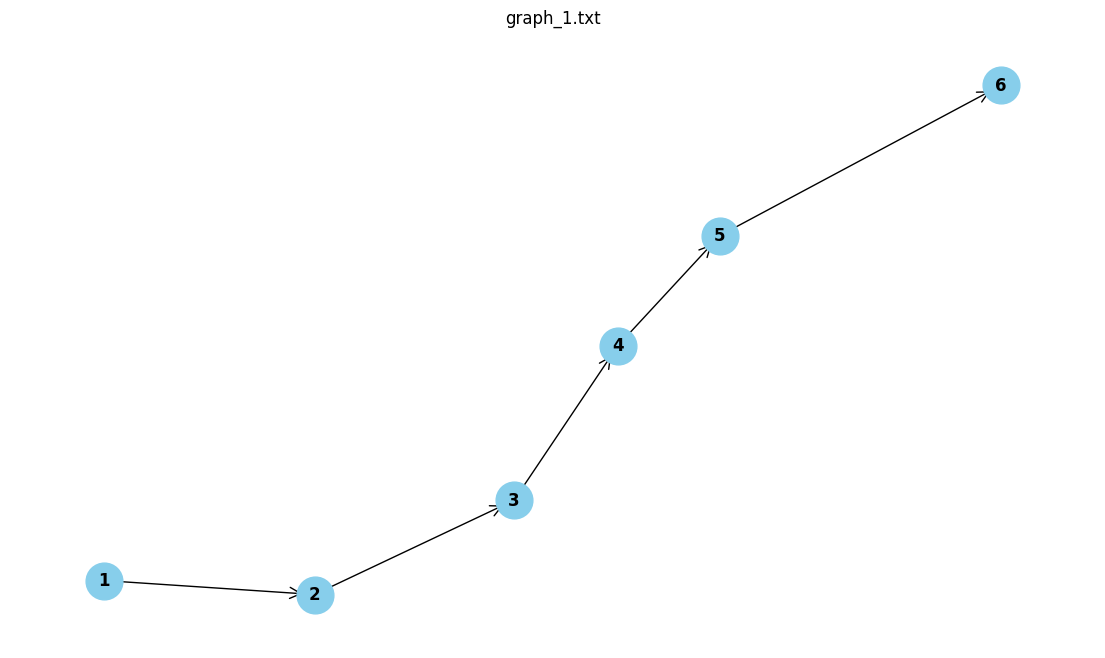


graph_1.txt:
Hubs: {1: 1.0524392898526698, 3: 0.6195332522186352, 5: 0.2265666735970954, 2: 0.015046723551667909, 6: -0.0, 4: -0.9135859392200683}
Authorities: {2: 1.0524392898526698, 4: 0.6195332522186352, 6: 0.2265666735970954, 3: 0.015046723551667909, 1: -0.0, 5: -0.9135859392200683}


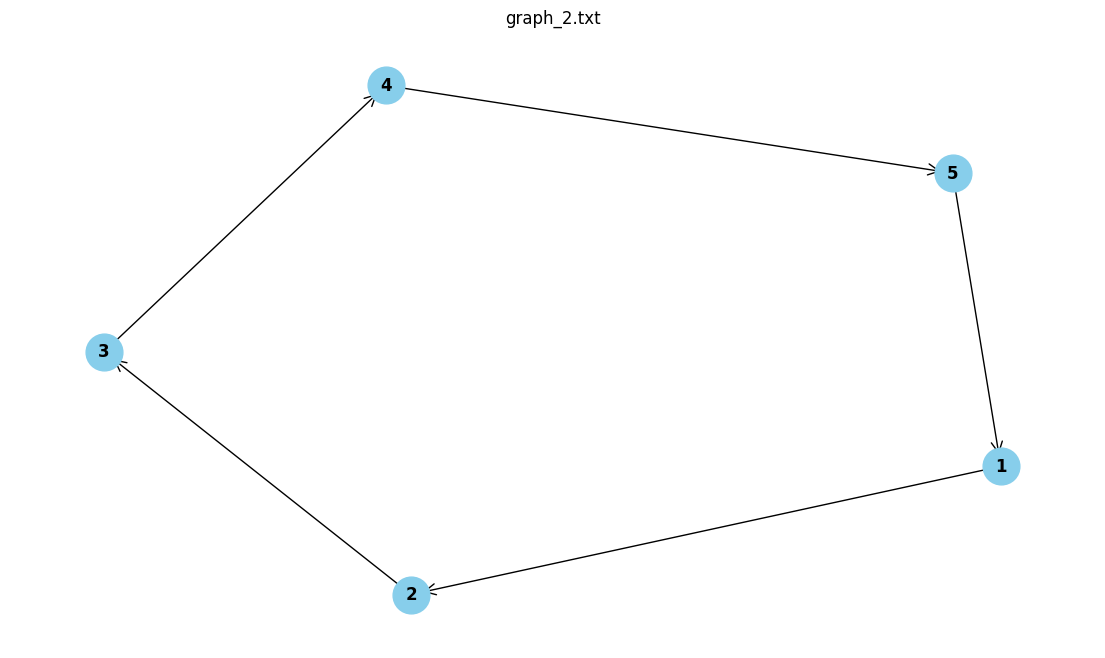


graph_2.txt:
Hubs: {3: 1.0609054729052863, 1: 0.4853942347780931, 4: 0.04154263437129308, 2: -0.09975474074109952, 5: -0.4880876013135729}
Authorities: {4: 1.0609054729052863, 2: 0.4853942347780931, 5: 0.04154263437129308, 3: -0.09975474074109952, 1: -0.4880876013135729}


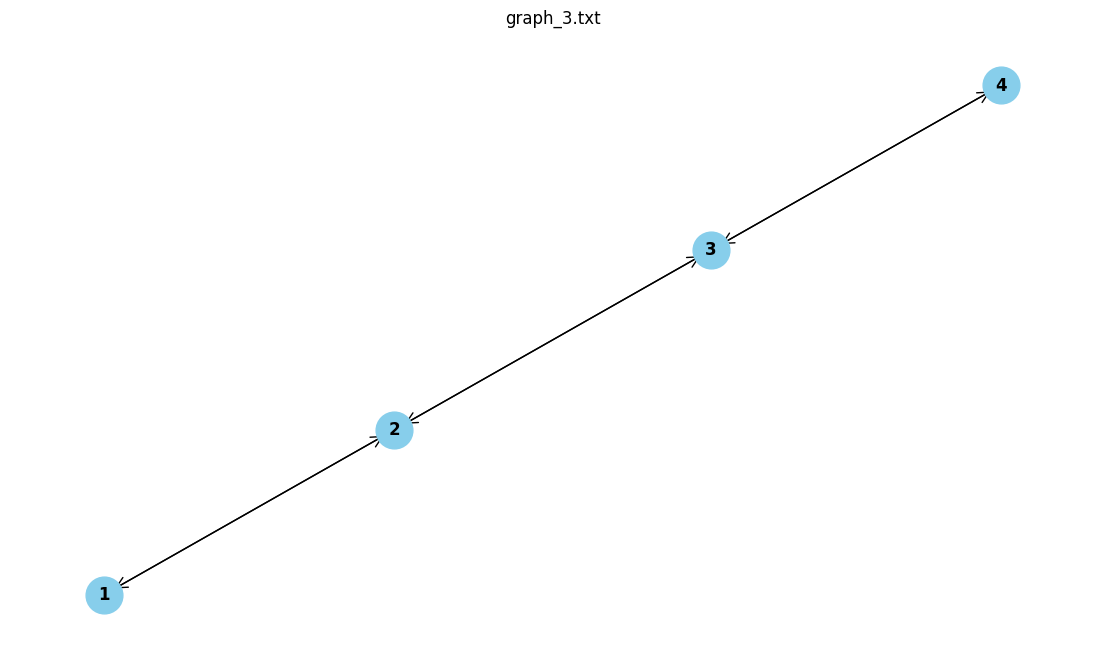


graph_3.txt:
Hubs: {2: 0.33877166183166985, 3: 0.27926232691822506, 4: 0.2093724014372574, 1: 0.17259360981284774}
Authorities: {3: 0.33877166183166985, 2: 0.27926232691822506, 1: 0.20937240143725744, 4: 0.17259360981284777}


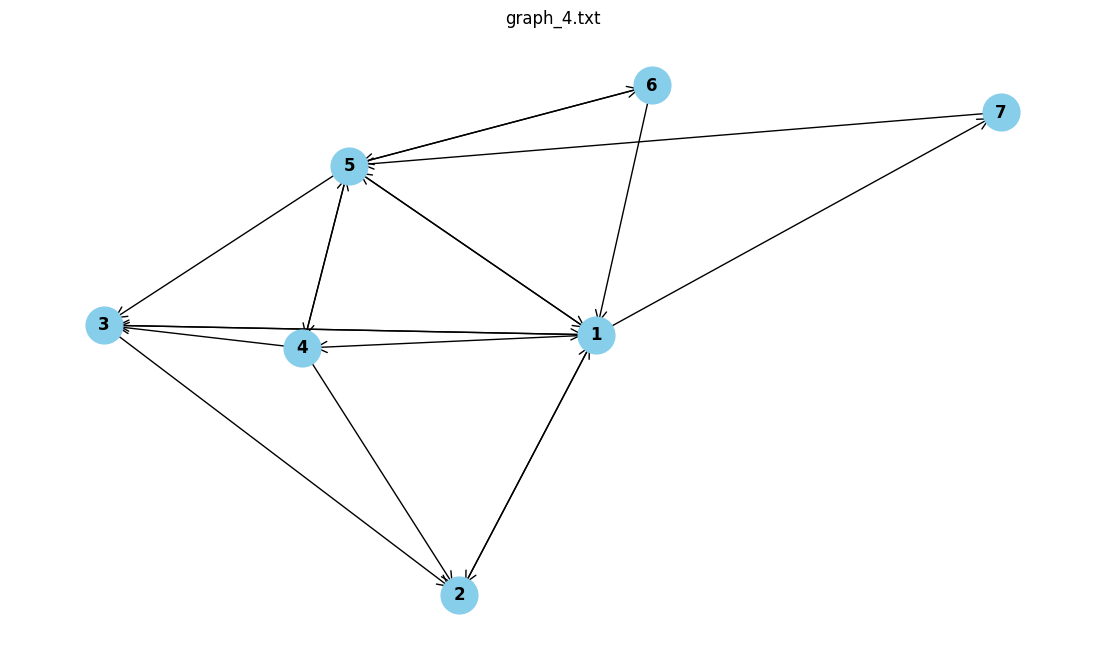


graph_4.txt:
Hubs: {1: 0.2754531769299128, 4: 0.19865955678939382, 5: 0.18373459903205097, 6: 0.11673471384210078, 3: 0.10868323956444093, 7: 0.06897240771541654, 2: 0.04776230612668424}
Authorities: {5: 0.20142536390917531, 3: 0.2008232055104341, 2: 0.17791203169269668, 4: 0.14017775327021467, 1: 0.1394838923472646, 7: 0.08408849166833336, 6: 0.05608926160188133}


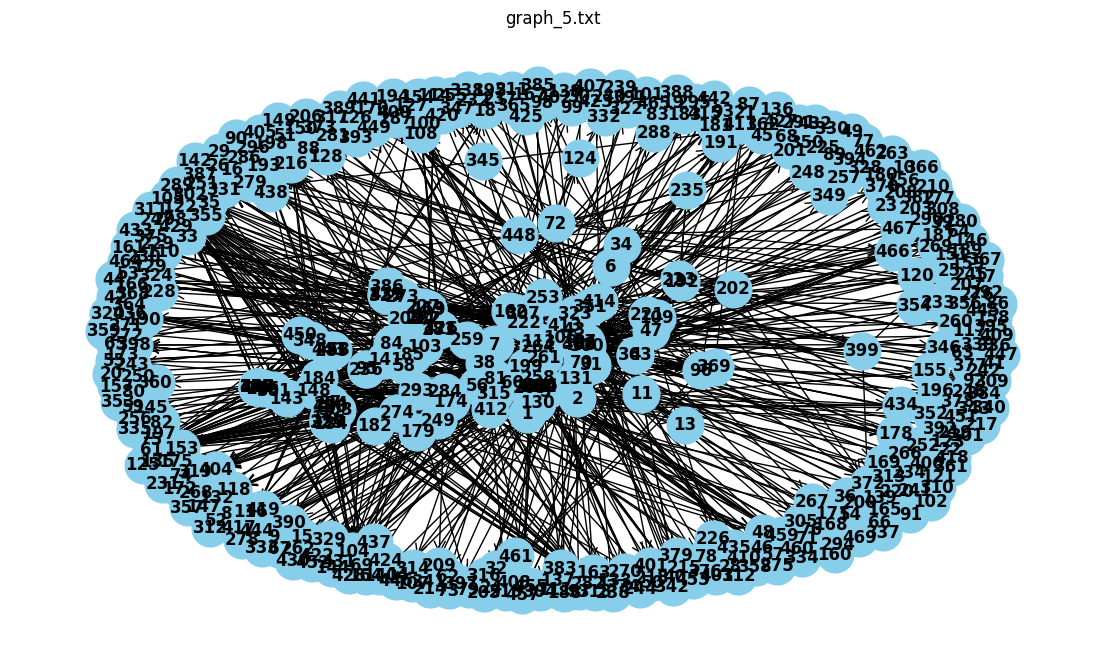


graph_5.txt:
Hubs: {274: 0.028236987977073354, 176: 0.027923728895284217, 412: 0.027324388199998377, 293: 0.026124668501052672, 254: 0.025697919326668633, 325: 0.025563652295699915, 115: 0.02543914279594687, 182: 0.025149235878543535, 37: 0.024875070580581735, 450: 0.024697783835551258, 299: 0.0243074710147525, 297: 0.024294678665384872, 326: 0.023901207068550312, 416: 0.023901207068550312, 456: 0.023901207068550312, 285: 0.023689080487229744, 224: 0.022633248656000016, 186: 0.022514993980997433, 440: 0.022514993980997433, 179: 0.022487186086573685, 283: 0.022338034023911088, 348: 0.022226109352307916, 426: 0.022221321792545486, 371: 0.022221321792545486, 134: 0.021287426706091416, 185: 0.021206872076755773, 212: 0.020763080836965254, 95: 0.020442383011108945, 236: 0.020442383011108945, 38: 0.020096876463418418, 58: 0.019285069313679366, 443: 0.019055749570088012, 184: 0.01841419538847242, 315: 0.01771456194482063, 458: 0.017346121431853063, 303: 0.0166576997333547, 56: 0.016579513190

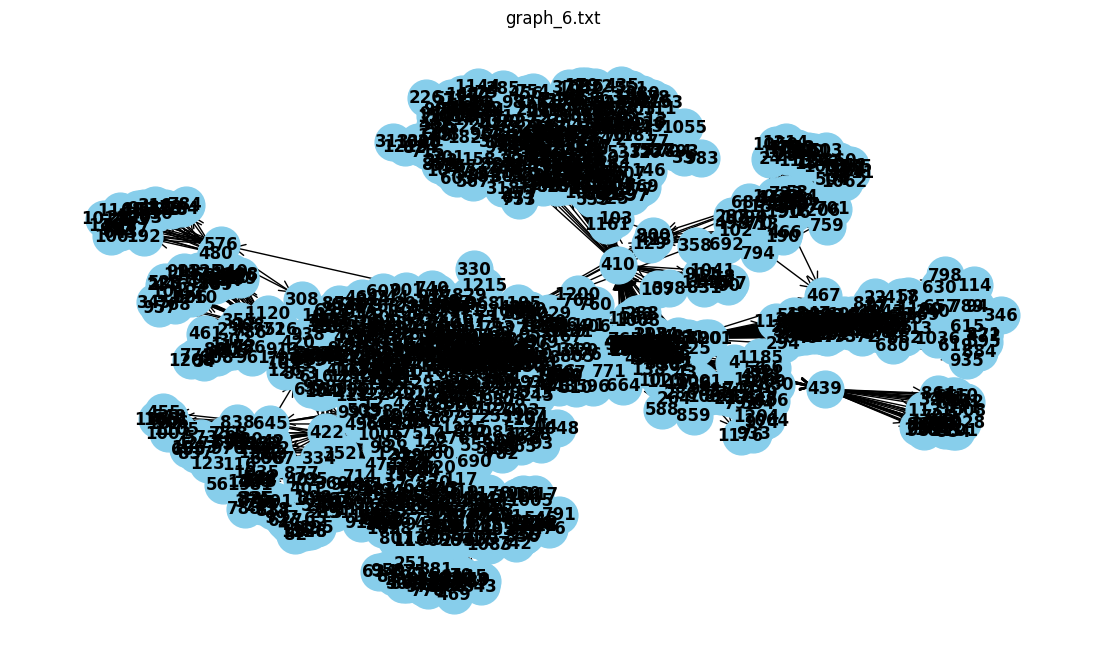


graph_6.txt:
Hubs: {171: 0.0161514564216298, 857: 0.015518973821709385, 185: 0.0154181498161244, 91: 0.015291453223826882, 79: 0.015248839274678417, 1199: 0.015069175508707146, 499: 0.0150423305382059, 835: 0.014924742983227953, 386: 0.014821377494355095, 755: 0.014666942616572684, 462: 0.014501889417186584, 8: 0.014477549648701987, 194: 0.014445623455835038, 50: 0.01438292476479251, 140: 0.014312703806945654, 593: 0.014185617838661266, 169: 0.014051808653129211, 267: 0.014013032671614417, 1150: 0.013937144578844485, 501: 0.01387562382805293, 606: 0.013718661993406872, 336: 0.013699564499806006, 1071: 0.013447368886809497, 662: 0.013208866570891901, 506: 0.012986844290584759, 397: 0.012518885502196332, 250: 0.012362231654062, 81: 0.012314962258972353, 9: 0.012232076054967993, 896: 0.012164651955970681, 803: 0.012020145294610053, 929: 0.011920049967975528, 449: 0.011811668660984266, 914: 0.011693270651104343, 905: 0.011676311037018309, 180: 0.01155956665652342, 266: 0.01135938784260517

In [ ]:
for filename in files:
    try:
        G = read_graph_from_file(filename)
        draw_graph(G, filename)
        hubs, auths = compute_hits(G)

        # сортировка по значениям
        hubs_sorted = dict(sorted(hubs.items(), key=lambda x: x[1], reverse=True))
        auths_sorted = dict(sorted(auths.items(), key=lambda x: x[1], reverse=True))

        print(f"\n{filename}:")
        print("Hubs:", hubs_sorted)
        print("Authorities:", auths_sorted)

    except FileNotFoundError:
        print(f"Файл {filename} не найден.")


Graph 1 Узел 1 — главный хаб, инициирующий переходы, а узел 2 — главный авторитет, получающий ссылки; остальные узлы играют второстепенные роли. Конец цепочки (узел 6) почти незначим.

Graph 2 В цикле 1-2-3-4-5-1 узел 3 выделяется как хаб, а узел 4 как авторитет, остальные узлы имеют меньший вес из-за особенностей итераций и нормировки.

Graph 3 Узел 2 — сильнейший хаб, узел 3 — главный авторитет, узлы 1 и 4 поддерживают структуру, но менее значимы.

Graph 4 Хабы распределены между узлами 1, 4, 5, а авторитеты — между узлами 3 и 5, которые имеют почти равные значения.

Graph 5 В большом графе вес концентрируется на узлах 274,176,412 и др. как хабах, и на узлах 61, 122, 212 и др. как авторитетах, большинство узлов остаются малозначимыми.

Graph 6 Сильные хабы — узлы 171, 857, 185и др., а авторитеты — узлы 761, 1151, 62, 78 и др., сеть имеет несколько центров влияния.

2.Как можно объяснить равенство значений Authority centrality для узлов 3 и 5 графа 4 ?


Узлы 3 и 5 имеют равную Authority Centrality, потому что получают одинаково сильные входящие ссылки от одних и тех же и эквивалентных хабов в структуре графа.

3. Как можно увеличить метрики для узла 1 в графах 1, 2 и 3


Graph 1

Hub Centrality узла 1 уже максимальна (1.052).

Authority Centrality узла 1 равна 0.
Как увеличить: Добавить входящие рёбра к узлу 1 от существующих хабов, особенно от узлов 1 (петля) или 3 (Hub = 0.619).

Graph 2

Hub Centrality узла 1 = 0.485.
Как увеличить: Добавить исходящие рёбра от узла 1 к авторитетным узлам 4 (Authority = 1.061) или 2 (0.485).

Authority Centrality узла 1 отрицательна (−0.488).
Как увеличить: Добавить входящие рёбра к узлу 1 от сильных хабов, например от узла 3 (Hub = 1.061).

Graph 3

Hub Centrality узла 1 = 0.172.
Как увеличить: Добавить исходящие рёбра от узлов с высокой метрикой Authority.

Authority Centrality узла 1 = 0.209.
Как увеличить: Добавить входящие рёбра к узлам с высокой метрикой Hub Centrality.